In [3]:
import yfinance as yf
import pandas as pd
import numpy as np

assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

state_tickers = [
    "SPY",
    "^VIX"
]

all_tickers = assets + state_tickers

In [4]:
data = yf.download(
    all_tickers,
    start="2010-01-01",
    auto_adjust=False,
    progress=False
)

print(data.shape)
print(data.head())
print(data.tail())

(4219, 66)
Price       Adj Close                                                       \
Ticker            SPY        XLB        XLE       XLF        XLI       XLK   
Date                                                                         
2010-01-04  84.369003  11.916906  17.043320  8.879744  20.815496  9.356696   
2010-01-05  84.592308  11.955439  17.182425  9.042952  20.888994  9.344633   
2010-01-06  84.651848  12.158612  17.388186  9.061086  20.933096  9.240087   
2010-01-07  85.009201  12.064030  17.362097  9.254519  21.160954  9.203896   
2010-01-08  85.292099  12.232175  17.475134  9.200117  21.499052  9.264214   

Price                                                  ...      Volume  \
Ticker            XLP       XLU        XLV        XLY  ...         XLB   
Date                                                   ...               
2010-01-04  17.019960  8.765263  23.788498  12.257140  ...  15135000.0   
2010-01-05  17.026348  8.660913  23.555199  12.302083  ...  17678400

In [5]:
data.to_csv("../data/raw/yahoo_market_data.csv")

In [6]:
print(data.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 4219 entries, 2010-01-04 to 2026-10-08
Data columns (total 66 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, SPY)   4216 non-null   float64
 1   (Adj Close, XLB)   4216 non-null   float64
 2   (Adj Close, XLE)   4216 non-null   float64
 3   (Adj Close, XLF)   4216 non-null   float64
 4   (Adj Close, XLI)   4216 non-null   float64
 5   (Adj Close, XLK)   4216 non-null   float64
 6   (Adj Close, XLP)   4216 non-null   float64
 7   (Adj Close, XLU)   4216 non-null   float64
 8   (Adj Close, XLV)   4216 non-null   float64
 9   (Adj Close, XLY)   4216 non-null   float64
 10  (Adj Close, ^VIX)  4219 non-null   float64
 11  (Close, SPY)       4216 non-null   float64
 12  (Close, XLB)       4216 non-null   float64
 13  (Close, XLE)       4216 non-null   float64
 14  (Close, XLF)       4216 non-null   float64
 15  (Close, XLI)       4216 non-null   float64
 16  (Close, XLK)     

In [7]:
print(data.isnull().sum())

Price      Ticker
Adj Close  SPY       3
           XLB       3
           XLE       3
           XLF       3
           XLI       3
                    ..
Volume     XLP       3
           XLU       3
           XLV       3
           XLY       3
           ^VIX      0
Length: 66, dtype: int64


In [8]:
print(data.index.min())
print(data.index.max())

2010-01-04 00:00:00
2026-10-08 00:00:00


In [9]:
import pandas as pd
import yfinance as yf

try:
    data
except NameError:
    try:
        data = pd.read_csv("../data/raw/yahoo_market_data.csv", header=[0, 1], index_col=0, parse_dates=True)
    except FileNotFoundError:
        assets = [
            "XLB", "XLE", "XLF",
            "XLI", "XLK", "XLP",
            "XLU", "XLV", "XLY"
        ]

        state_tickers = [
            "SPY",
            "^VIX"
        ]

        all_tickers = assets + state_tickers
        data = yf.download(
            all_tickers,
            start="2010-01-01",
            auto_adjust=False,
            progress=False
        )

print(data.columns)

MultiIndex([('Adj Close',  'SPY'),
            ('Adj Close',  'XLB'),
            ('Adj Close',  'XLE'),
            ('Adj Close',  'XLF'),
            ('Adj Close',  'XLI'),
            ('Adj Close',  'XLK'),
            ('Adj Close',  'XLP'),
            ('Adj Close',  'XLU'),
            ('Adj Close',  'XLV'),
            ('Adj Close',  'XLY'),
            ('Adj Close', '^VIX'),
            (    'Close',  'SPY'),
            (    'Close',  'XLB'),
            (    'Close',  'XLE'),
            (    'Close',  'XLF'),
            (    'Close',  'XLI'),
            (    'Close',  'XLK'),
            (    'Close',  'XLP'),
            (    'Close',  'XLU'),
            (    'Close',  'XLV'),
            (    'Close',  'XLY'),
            (    'Close', '^VIX'),
            (     'High',  'SPY'),
            (     'High',  'XLB'),
            (     'High',  'XLE'),
            (     'High',  'XLF'),
            (     'High',  'XLI'),
            (     'High',  'XLK'),
            (     'H

In [10]:
prices = data["Adj Close"].copy()

In [11]:
print(prices.head())
print(prices.shape)
print(prices.isnull().sum())

Ticker            SPY        XLB        XLE       XLF        XLI       XLK  \
Date                                                                         
2010-01-04  84.369003  11.916906  17.043320  8.879744  20.815496  9.356696   
2010-01-05  84.592308  11.955439  17.182425  9.042952  20.888994  9.344633   
2010-01-06  84.651848  12.158612  17.388186  9.061086  20.933096  9.240087   
2010-01-07  85.009201  12.064030  17.362097  9.254519  21.160954  9.203896   
2010-01-08  85.292099  12.232175  17.475134  9.200117  21.499052  9.264214   

Ticker            XLP       XLU        XLV        XLY       ^VIX  
Date                                                              
2010-01-04  17.019960  8.765263  23.788498  12.257140  20.040001  
2010-01-05  17.026348  8.660913  23.555199  12.302083  19.350000  
2010-01-06  17.013588  8.711678  23.796013  12.318425  19.160000  
2010-01-07  17.013588  8.672194  23.878803  12.420572  19.059999  
2010-01-08  16.956152  8.663730  23.916420  12.4164

In [12]:
missing_rows = prices[prices.isnull().any(axis=1)]

print(missing_rows)

Ticker      SPY  XLB  XLE  XLF  XLI  XLK  XLP  XLU  XLV  XLY   ^VIX
Date                                                               
2026-05-25  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  16.59
2026-09-07  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  15.30
2026-10-08  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  15.94


In [13]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

In [14]:
asset_prices = prices[assets].copy()

In [15]:
print(asset_prices.head())
print(asset_prices.shape)

Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916906  17.043320  8.879744  20.815496  9.356696  17.019960   
2010-01-05  11.955439  17.182425  9.042952  20.888994  9.344633  17.026348   
2010-01-06  12.158612  17.388186  9.061086  20.933096  9.240087  17.013588   
2010-01-07  12.064030  17.362097  9.254519  21.160954  9.203896  17.013588   
2010-01-08  12.232175  17.475134  9.200117  21.499052  9.264214  16.956152   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765263  23.788498  12.257140  
2010-01-05  8.660913  23.555199  12.302083  
2010-01-06  8.711678  23.796013  12.318425  
2010-01-07  8.672194  23.878803  12.420572  
2010-01-08  8.663730  23.916420  12.416483  
(4219, 9)


In [16]:
spy_price = prices["SPY"].copy()

print(spy_price.head())

Date
2010-01-04    84.369003
2010-01-05    84.592308
2010-01-06    84.651848
2010-01-07    85.009201
2010-01-08    85.292099
Name: SPY, dtype: float64


In [17]:
vix = prices["^VIX"].copy()

print(vix.head())

Date
2010-01-04    20.040001
2010-01-05    19.350000
2010-01-06    19.160000
2010-01-07    19.059999
2010-01-08    18.129999
Name: ^VIX, dtype: float64


In [18]:
print("Portfolio assets:")
print(asset_prices.head())

print("\nAsset price shape:")
print(asset_prices.shape)

print("\nSPY:")
print(spy_price.head())

print("\nVIX:")
print(vix.head())

print("\nMissing rows:")
print(prices[prices.isnull().any(axis=1)])

Portfolio assets:
Ticker            XLB        XLE       XLF        XLI       XLK        XLP  \
Date                                                                         
2010-01-04  11.916906  17.043320  8.879744  20.815496  9.356696  17.019960   
2010-01-05  11.955439  17.182425  9.042952  20.888994  9.344633  17.026348   
2010-01-06  12.158612  17.388186  9.061086  20.933096  9.240087  17.013588   
2010-01-07  12.064030  17.362097  9.254519  21.160954  9.203896  17.013588   
2010-01-08  12.232175  17.475134  9.200117  21.499052  9.264214  16.956152   

Ticker           XLU        XLV        XLY  
Date                                        
2010-01-04  8.765263  23.788498  12.257140  
2010-01-05  8.660913  23.555199  12.302083  
2010-01-06  8.711678  23.796013  12.318425  
2010-01-07  8.672194  23.878803  12.420572  
2010-01-08  8.663730  23.916420  12.416483  

Asset price shape:
(4219, 9)

SPY:
Date
2010-01-04    84.369003
2010-01-05    84.592308
2010-01-06    84.651848
2010-01

In [19]:
missing_rows = prices[prices.isnull().any(axis=1)]

print("Number of rows containing missing values:",
      len(missing_rows))

print("\nDates with missing values:")
print(missing_rows.index.tolist())

print("\nMissing values on each affected date:")
for date, row in missing_rows.iterrows():
    missing = row[row.isna()].index.tolist()
    print(date.date(), "->", missing)

Number of rows containing missing values: 3

Dates with missing values:
[Timestamp('2026-05-25 00:00:00'), Timestamp('2026-09-07 00:00:00'), Timestamp('2026-10-08 00:00:00')]

Missing values on each affected date:
2026-05-25 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
2026-09-07 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
2026-10-08 -> ['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']


In [20]:
#Keep only dates where all 11 required serieare available
clean_prices = prices.dropna().copy()

print("Before cleaning:", prices.shape)
print("After cleaning:", clean_prices.shape)

print("\nMissing values after cleaning:")
print(clean_prices.isnull().sum())

print("\nData range:")
print(clean_prices.index.min())
print(clean_prices.index.max())
      

Before cleaning: (4219, 11)
After cleaning: (4216, 11)

Missing values after cleaning:
Ticker
SPY     0
XLB     0
XLE     0
XLF     0
XLI     0
XLK     0
XLP     0
XLU     0
XLV     0
XLY     0
^VIX    0
dtype: int64

Data range:
2010-01-04 00:00:00
2026-10-07 00:00:00


In [21]:
assets = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

asset_prices = clean_prices[assets].copy()

spy_price = clean_prices["SPY"].copy()
vix = clean_prices["^VIX"].copy()

In [22]:
print("Asset prices:", asset_prices.shape)
print("SPY price:", spy_price.shape)
print("VIX price:", vix.shape)

print("\nAsset mssing values:")
print(asset_prices.isnull().sum())

Asset prices: (4216, 9)
SPY price: (4216,)
VIX price: (4216,)

Asset mssing values:
Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64


In [23]:
prices.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,84.369003,11.916906,17.043320,8.879744,20.815496,9.356696,17.019960,8.765263,23.788498,12.257140,20.040001
2010-01-05,84.592308,11.955439,17.182425,9.042952,20.888994,9.344633,17.026348,8.660913,23.555199,12.302083,19.350000
2010-01-06,84.651848,12.158612,17.388186,9.061086,20.933096,9.240087,17.013588,8.711678,23.796013,12.318425,19.160000
2010-01-07,85.009201,12.064030,17.362097,9.254519,21.160954,9.203896,17.013588,8.672194,23.878803,12.420572,19.059999
2010-01-08,85.292099,12.232175,17.475134,9.200117,21.499052,9.264214,16.956152,8.663730,23.916420,12.416483,18.129999


In [24]:
prices.shape

(4219, 11)

In [25]:
prices.index

DatetimeIndex(['2010-01-04', '2010-01-05', '2010-01-06', '2010-01-07',
               '2010-01-08', '2010-01-11', '2010-01-12', '2010-01-13',
               '2010-01-14', '2010-01-15',
               ...
               '2026-09-25', '2026-09-28', '2026-09-29', '2026-09-30',
               '2026-10-01', '2026-10-02', '2026-10-05', '2026-10-06',
               '2026-10-07', '2026-10-08'],
              dtype='datetime64[s]', name='Date', length=4219, freq=None)

In [26]:
returns = np.log(prices / prices.shift(1))

In [27]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.002643,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009856,0.003660,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010171,0.001328,-0.009868
2010-01-07,0.004213,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006489,-0.005896,0.015851,0.006532,-0.003382,-0.000976,0.001574,-0.000329,-0.050024


In [28]:
returns = returns.dropna()

In [29]:
returns.head()

Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,^VIX
Date,,,,,,,,,,,
2010-01-05,0.002643,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009856,0.003660,-0.035038
2010-01-06,0.000704,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010171,0.001328,-0.009868
2010-01-07,0.004213,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258,-0.005233
2010-01-08,0.003322,0.013841,0.006489,-0.005896,0.015851,0.006532,-0.003382,-0.000976,0.001574,-0.000329,-0.050024
2010-01-11,0.001396,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976,-0.032514


In [30]:
print(returns.columns.tolist())
print(returns.shape)


['SPY', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', '^VIX']
(4213, 11)


In [31]:
sector_tickers = [
    "XLB", "XLE", "XLF",
    "XLI", "XLK", "XLP",
    "XLU", "XLV", "XLY"
]

sector_returns = returns[sector_tickers].copy()

In [32]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009856,0.003660
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010171,0.001328
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258
2010-01-08,0.013841,0.006489,-0.005896,0.015851,0.006532,-0.003382,-0.000976,0.001574,-0.000329
2010-01-11,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976


In [33]:
sector_returns.shape

(4213, 9)

In [34]:
market_features = returns[["SPY", "^VIX"]].copy()
market_features.head()

Ticker,SPY,^VIX
Date,,
2010-01-05,0.002643,-0.035038
2010-01-06,0.000704,-0.009868
2010-01-07,0.004213,-0.005233
2010-01-08,0.003322,-0.050024
2010-01-11,0.001396,-0.032514


In [35]:
sector_returns.isna().sum()

Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

In [36]:
np.isinf(sector_returns).sum()

Ticker
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

In [37]:
sector_returns.index.duplicated().sum()

np.int64(0)

In [38]:
sector_returns.index.is_monotonic_increasing

True

In [39]:
sector_returns.dtypes

Ticker
XLB    float64
XLE    float64
XLF    float64
XLI    float64
XLK    float64
XLP    float64
XLU    float64
XLV    float64
XLY    float64
dtype: object

In [40]:
sector_returns.min()

Ticker
XLB   -0.116628
XLE   -0.224910
XLF   -0.147449
XLI   -0.120408
XLK   -0.148662
XLP   -0.098668
XLU   -0.120561
XLV   -0.103817
XLY   -0.135460
dtype: float64

In [41]:
sector_returns.max()

Ticker
XLB    0.111184
XLE    0.148742
XLF    0.123602
XLI    0.119126
XLK    0.125978
XLP    0.081678
XLU    0.120388
XLV    0.074232
XLY    0.103351
dtype: float64

In [42]:
sector_returns.abs().max().sort_values(ascending=False)

Ticker
XLE    0.224910
XLK    0.148662
XLF    0.147449
XLY    0.135460
XLU    0.120561
XLI    0.120408
XLB    0.116628
XLV    0.103817
XLP    0.098668
dtype: float64

In [43]:
print("=== SECTOR RETURN DATA VALIDATION ===")
print("Observations:", sector_returns.shape[0])
print("Assets:", sector_returns.shape[1])
print("Start date:", sector_returns.index.min())
print("End date:", sector_returns.index.max())
print("Missing values:", sector_returns.isna().sum().sum())
print("Infinite values:", np.isinf(sector_returns.to_numpy()).sum())
print("Duplicate dates:", sector_returns.index.duplicated().sum())
print("Chronological:", sector_returns.index.is_monotonic_increasing)

=== SECTOR RETURN DATA VALIDATION ===
Observations: 4213
Assets: 9
Start date: 2010-01-05 00:00:00
End date: 2026-10-07 00:00:00
Missing values: 0
Infinite values: 0
Duplicate dates: 0
Chronological: True


In [44]:
summary_stats = sector_returns.describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
XLB,4213.0,0.000334,0.013075,-0.116628,-0.006290,0.000725,0.007390,0.111184
XLE,4213.0,0.000316,0.017153,-0.224910,-0.007690,0.000668,0.008879,0.148742
XLF,4213.0,0.000431,0.013695,-0.147449,-0.005679,0.000762,0.007315,0.123602
XLI,4213.0,0.000493,0.012221,-0.120408,-0.005118,0.000882,0.006664,0.119126
XLK,4213.0,0.000722,0.013889,-0.148662,-0.005279,0.001209,0.007645,0.125978
XLP,4213.0,0.000377,0.008694,-0.098668,-0.003841,0.000571,0.005023,0.081678
XLU,4213.0,0.000365,0.010996,-0.120561,-0.005173,0.000941,0.006253,0.120388
XLV,4213.0,0.000473,0.010200,-0.103817,-0.004435,0.000675,0.005963,0.074232
XLY,4213.0,0.000525,0.012828,-0.135460,-0.005311,0.001231,0.007280,0.103351


In [45]:
summary_stats["skewness"] = sector_returns.skew()
summary_stats["kurtosis"] = sector_returns.kurt()

summary_stats

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Ticker,,,,,,,,,,
XLB,4213.0,0.000334,0.013075,-0.116628,-0.006290,0.000725,0.007390,0.111184,-0.392665,7.096096
XLE,4213.0,0.000316,0.017153,-0.224910,-0.007690,0.000668,0.008879,0.148742,-0.822507,15.075532
XLF,4213.0,0.000431,0.013695,-0.147449,-0.005679,0.000762,0.007315,0.123602,-0.510497,12.067923
XLI,4213.0,0.000493,0.012221,-0.120408,-0.005118,0.000882,0.006664,0.119126,-0.482068,10.566936
XLK,4213.0,0.000722,0.013889,-0.148662,-0.005279,0.001209,0.007645,0.125978,-0.294637,9.315588
XLP,4213.0,0.000377,0.008694,-0.098668,-0.003841,0.000571,0.005023,0.081678,-0.449406,12.606032
XLU,4213.0,0.000365,0.010996,-0.120561,-0.005173,0.000941,0.006253,0.120388,-0.308609,14.602354
XLV,4213.0,0.000473,0.010200,-0.103817,-0.004435,0.000675,0.005963,0.074232,-0.380476,7.463004
XLY,4213.0,0.000525,0.012828,-0.135460,-0.005311,0.001231,0.007280,0.103351,-0.557214,8.148250


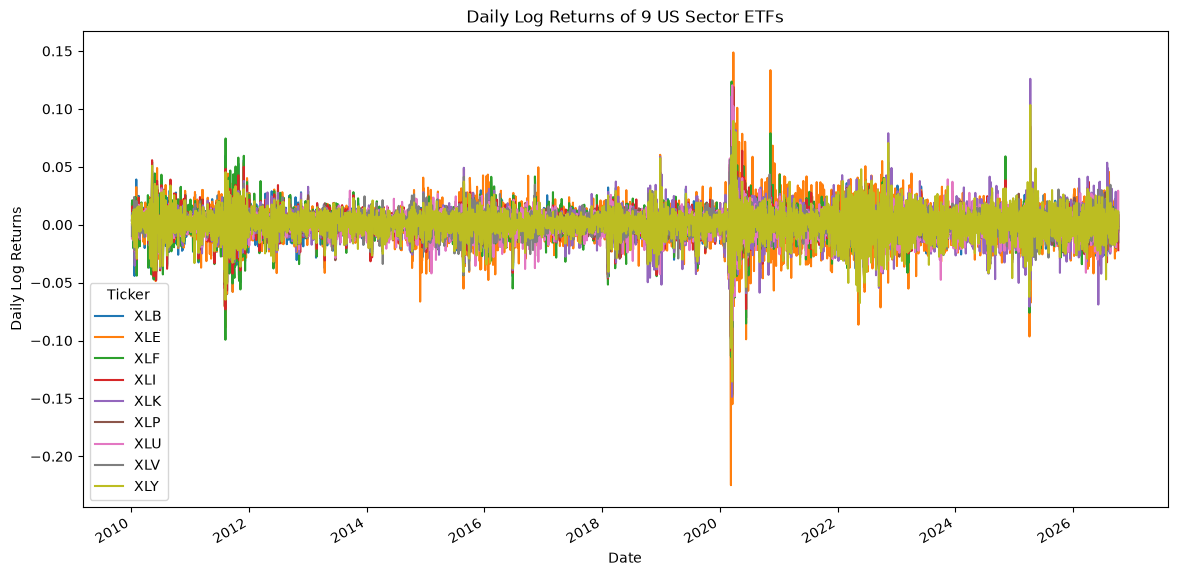

In [46]:
import matplotlib.pyplot as plt

sector_returns.plot(
    figsize=(14,7),
    title = "Daily Log Returns of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Daily Log Returns")
plt.show()

In [47]:
correlation_matrix = sector_returns.corr()
correlation_matrix

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,1.000000,0.695922,0.810450,0.873845,0.694742,0.637310,0.523104,0.694695,0.749843
XLE,0.695922,1.000000,0.681885,0.682971,0.483234,0.450459,0.396026,0.501883,0.521658
XLF,0.810450,0.681885,1.000000,0.862346,0.674045,0.624912,0.502552,0.695472,0.751118
XLI,0.873845,0.682971,0.862346,1.000000,0.752958,0.654739,0.553719,0.717978,0.797980
XLK,0.694742,0.483234,0.674045,0.752958,1.000000,0.525576,0.424916,0.638407,0.821747
XLP,0.637310,0.450459,0.624912,0.654739,0.525576,1.000000,0.682522,0.712624,0.603342
XLU,0.523104,0.396026,0.502552,0.553719,0.424916,0.682522,1.000000,0.552155,0.455017
XLV,0.694695,0.501883,0.695472,0.717978,0.638407,0.712624,0.552155,1.000000,0.664721
XLY,0.749843,0.521658,0.751118,0.797980,0.821747,0.603342,0.455017,0.664721,1.000000


In [48]:
np.allclose(correlation_matrix.values, correlation_matrix.values.T)

True

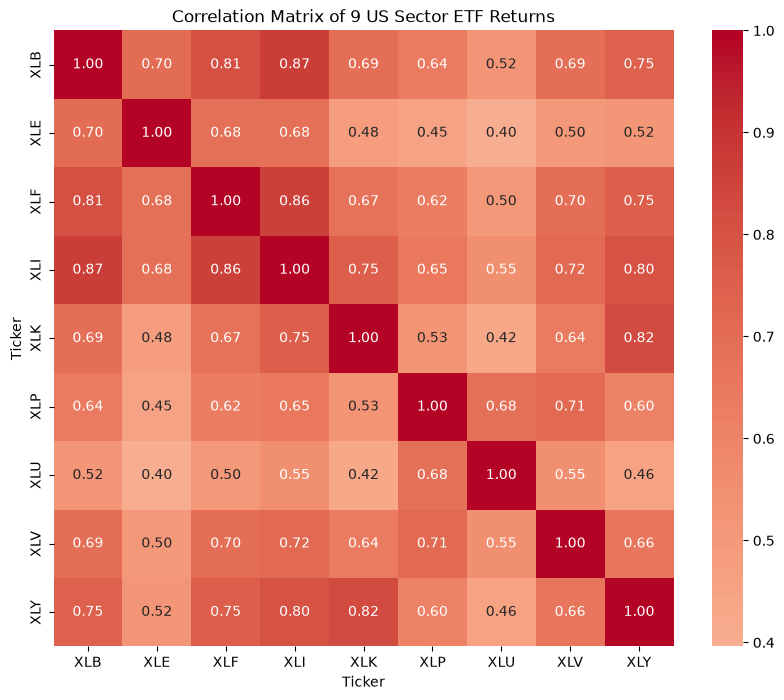

In [49]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center = 0
)

plt.title("Correlation Matrix of 9 US Sector ETF Returns")
plt.show()


In [50]:
rolling_vol_60 = (
    sector_returns.rolling(window=60).std() * np.sqrt(252)
)



In [51]:
rolling_vol_60.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
rolling_vol_60.dropna().head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-03-31,0.234929,0.200846,0.210134,0.166289,0.166572,0.094663,0.137361,0.142245,0.141338
2010-04-01,0.237497,0.203458,0.207690,0.166527,0.166588,0.095345,0.138391,0.141039,0.141714
2010-04-05,0.236271,0.205231,0.208443,0.166914,0.166635,0.095301,0.138414,0.139772,0.143314
2010-04-06,0.235708,0.205209,0.205240,0.165880,0.166405,0.095664,0.139176,0.139635,0.142676
2010-04-07,0.234377,0.205742,0.204961,0.163867,0.166128,0.096452,0.140636,0.139933,0.143025


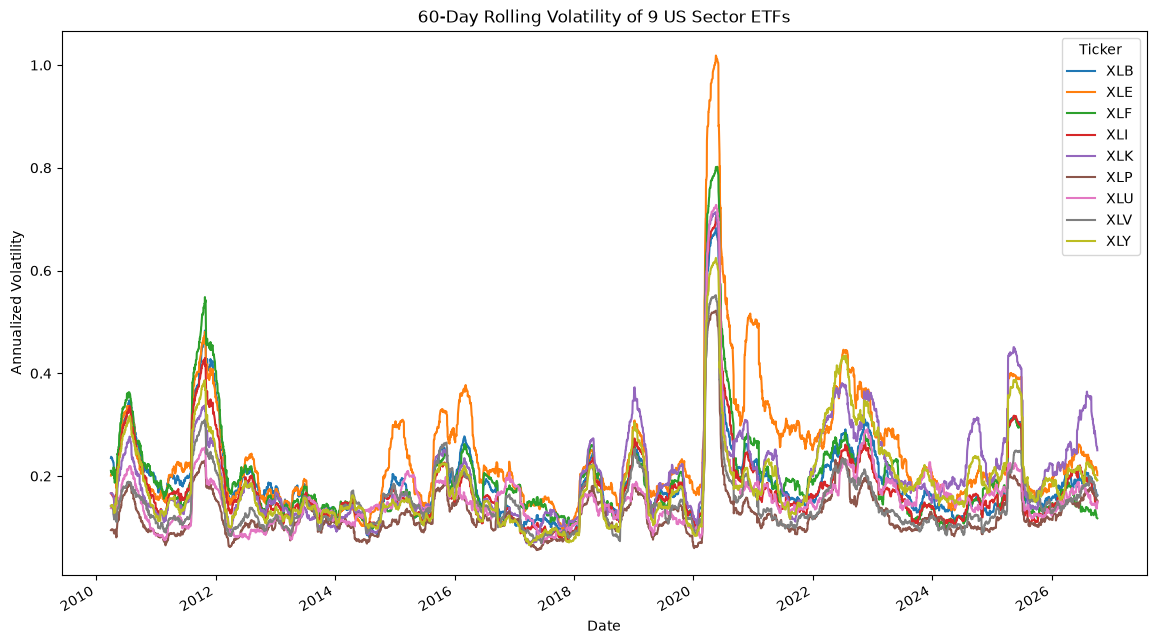

In [53]:
rolling_vol_60.plot(
    figsize=(14,8),
    title="60-Day Rolling Volatility of 9 US Sector ETFs"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [54]:
rolling_corr_XLK_XLF = (
    sector_returns["XLK"].rolling(window=60).corr(sector_returns["XLF"])
)

In [55]:
rolling_corr_XLK_XLF.dropna().head()

Date
2010-03-31    0.722812
2010-04-01    0.732390
2010-04-05    0.742691
2010-04-06    0.766503
2010-04-07    0.776928
dtype: float64

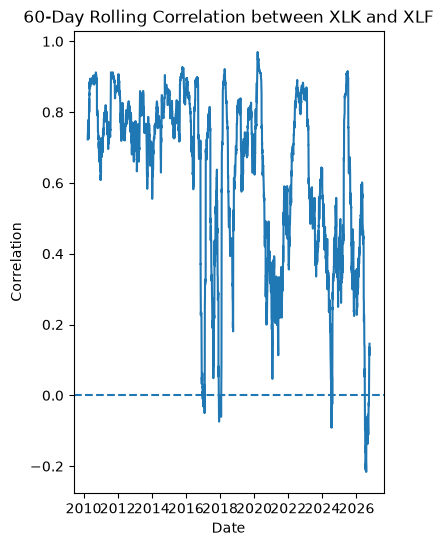

In [56]:
plt.figure(figsize=(4, 6))

plt.plot(
    rolling_corr_XLK_XLF.index,
    rolling_corr_XLK_XLF
)

plt.axhline(0, linestyle="--")

plt.title("60-Day Rolling Correlation between XLK and XLF")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.show()


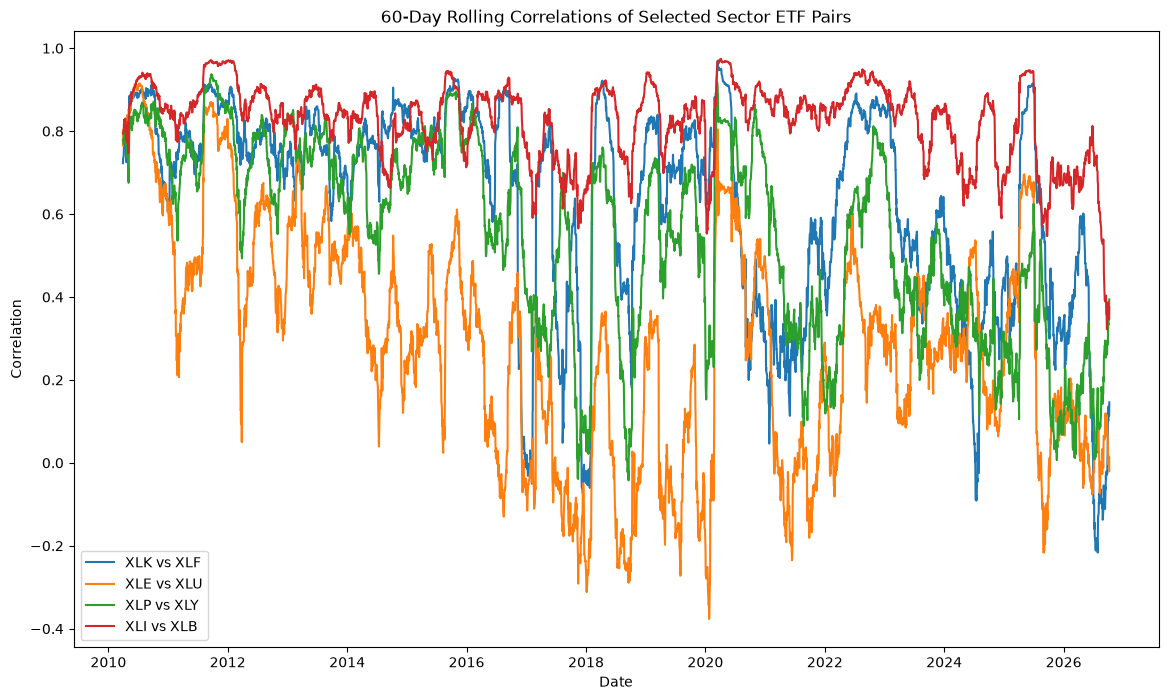

In [57]:
pairs = [
    ("XLK", "XLF"),
    ("XLE", "XLU"),
    ("XLP", "XLY"),
    ("XLI", "XLB")
     
]

plt.figure(figsize=(14, 8))

for etf1, etf2 in pairs:
    rolling_corr = (
        sector_returns[etf1].rolling(window=60).corr(sector_returns[etf2])
    )
    
    plt.plot(
        rolling_corr.index,
        rolling_corr,
        label=f"{etf1} vs {etf2}"
    )

plt.title("60-Day Rolling Correlations of Selected Sector ETF Pairs")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.legend()
plt.show()

In [58]:
spy_returns = returns["SPY"].copy()

In [59]:
spy_vol_60 = (
    spy_returns.rolling(window=60).std() * np.sqrt(252)
)

In [60]:
spy_vol_60.dropna().head()

Date
2010-03-31    0.141311
2010-04-01    0.141826
2010-04-05    0.142645
2010-04-06    0.142506
2010-04-07    0.143017
Name: SPY, dtype: float64

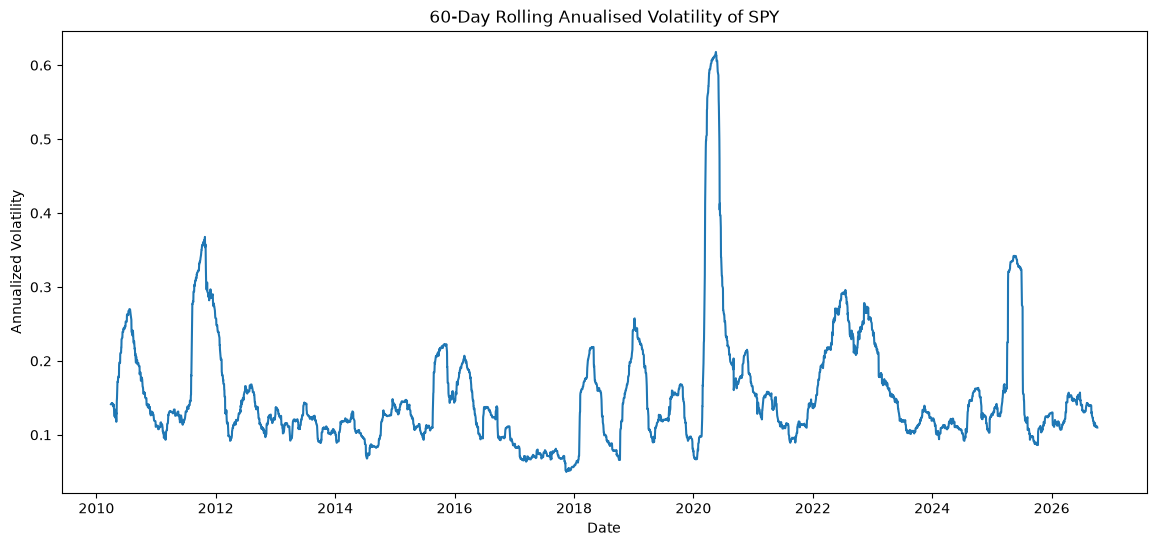

In [61]:
plt.figure(figsize=(14, 6))

plt.plot(
    spy_vol_60.index,
    spy_vol_60,
)

plt.title("60-Day Rolling Anualised Volatility of SPY")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.show()

In [62]:
sector_returns.to_csv(
    "sector_etf_daily_log_returns.csv"
)

In [63]:
summary_stats.to_csv(
    "sector_etf_summary_statistics.csv"
)

In [64]:
correlation_matrix.to_csv(
    "sector_etf_correlation_matrix.csv"
)

In [65]:
window = 60

historical_cov = (
    sector_returns.rolling(window=window).cov()
)

In [66]:
historical_cov.shape

(37917, 9)

In [67]:
historical_cov.tail(18)

Ticker                  XLB       XLE       XLF       XLI       XLK       XLP  \
Date       Ticker                                                               
2026-10-06 XLB     0.000103 -0.000021  0.000028  0.000032  0.000023  0.000042   
           XLE    -0.000021  0.000173 -0.000007 -0.000029 -0.000047 -0.000012   
           XLF     0.000028 -0.000007  0.000055  0.000030  0.000014  0.000026   
           XLI     0.000032 -0.000029  0.000030  0.000085  0.000080 -0.000004   
           XLK     0.000023 -0.000047  0.000014  0.000080  0.000259 -0.000069   
           XLP     0.000042 -0.000012  0.000026 -0.000004 -0.000069  0.000092   
           XLU     0.000018  0.000002  0.000011  0.000032  0.000013  0.000017   
           XLV     0.000039 -0.000013  0.000018 -0.000005 -0.000059  0.000059   
           XLY     0.000045 -0.000046  0.000043  0.000028  0.000037  0.000044   
2026-10-07 XLB     0.000106 -0.000016  0.000029  0.000037  0.000022  0.000043   
           XLE    -0.000016  0.000161 -0.000009 -0.000023 -0.000034 -0.000015   
           XLF     0.000029 -0.000009  0.000055  0.000032  0.000017  0.000025   
           XLI     0.000037 -0.000023  0.000032  0.000091  0.000079 -0.000003   
           XLK     0.000022 -0.000034  0.000017  0.000079  0.000248 -0.000067   
           XLP     0.000043 -0.000015  0.000025 -0.000003 -0.000067  0.000091   
           XLU     0.000018 -0.000002  0.000010  0.000032  0.000017  0.000016   
           XLV     0.000037 -0.000015  0.000017 -0.000008 -0.000058  0.000059   
           XLY     0.000044 -0.000041  0.000045  0.000028  0.000033  0.000045   

Ticker                      XLU           XLV       XLY  
Date       Ticker                                        
2026-10-06 XLB     1.750683e-05  3.921928e-05  0.000045  
           XLE     1.803168e-06 -1.251451e-05 -0.000046  
           XLF     1.074828e-05  1.811370e-05  0.000043  
           XLI     3.166778e-05 -4.791574e-06  0.000028  
           XLK     1.297222e-05 -5.871464e-05  0.000037  
           XLP     1.696266e-05  5.908693e-05  0.000044  
           XLU     8.981792e-05 -3.275351e-07  0.000006  
           XLV    -3.275351e-07  1.023947e-04  0.000027  
           XLY     5.961231e-06  2.704409e-05  0.000148  
2026-10-07 XLB     1.798284e-05  3.715504e-05  0.000044  
           XLE    -2.393021e-06 -1.487657e-05 -0.000041  
           XLF     9.659249e-06  1.715166e-05  0.000045  
           XLI     3.223805e-05 -7.724990e-06  0.000028  
           XLK     1.662183e-05 -5.837450e-05  0.000033  
           XLP     1.609132e-05  5.871084e-05  0.000045  
           XLU     8.862426e-05 -4.416094e-07  0.000007  
           XLV    -4.416094e-07  1.036920e-04  0.000027  
           XLY     7.297759e-06  2.702474e-05  0.000146

In [68]:
last_date = sector_returns.index[-1]

cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000106,-0.000016,0.000029,0.000037,0.000022,0.000043,1.798284e-05,3.715504e-05,0.000044
XLE,-0.000016,0.000161,-0.000009,-0.000023,-0.000034,-0.000015,-2.393021e-06,-1.487657e-05,-0.000041
XLF,0.000029,-0.000009,0.000055,0.000032,0.000017,0.000025,9.659249e-06,1.715166e-05,0.000045
XLI,0.000037,-0.000023,0.000032,0.000091,0.000079,-0.000003,3.223805e-05,-7.724990e-06,0.000028
XLK,0.000022,-0.000034,0.000017,0.000079,0.000248,-0.000067,1.662183e-05,-5.837450e-05,0.000033
XLP,0.000043,-0.000015,0.000025,-0.000003,-0.000067,0.000091,1.609132e-05,5.871084e-05,0.000045
XLU,0.000018,-0.000002,0.000010,0.000032,0.000017,0.000016,8.862426e-05,-4.416094e-07,0.000007
XLV,0.000037,-0.000015,0.000017,-0.000008,-0.000058,0.000059,-4.416094e-07,1.036920e-04,0.000027
XLY,0.000044,-0.000041,0.000045,0.000028,0.000033,0.000045,7.297759e-06,2.702474e-05,0.000146


In [69]:
cov_last.shape

(9, 9)

In [70]:
cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000106,-0.000016,0.000029,0.000037,0.000022,0.000043,1.798284e-05,3.715504e-05,0.000044
XLE,-0.000016,0.000161,-0.000009,-0.000023,-0.000034,-0.000015,-2.393021e-06,-1.487657e-05,-0.000041
XLF,0.000029,-0.000009,0.000055,0.000032,0.000017,0.000025,9.659249e-06,1.715166e-05,0.000045
XLI,0.000037,-0.000023,0.000032,0.000091,0.000079,-0.000003,3.223805e-05,-7.724990e-06,0.000028
XLK,0.000022,-0.000034,0.000017,0.000079,0.000248,-0.000067,1.662183e-05,-5.837450e-05,0.000033
XLP,0.000043,-0.000015,0.000025,-0.000003,-0.000067,0.000091,1.609132e-05,5.871084e-05,0.000045
XLU,0.000018,-0.000002,0.000010,0.000032,0.000017,0.000016,8.862426e-05,-4.416094e-07,0.000007
XLV,0.000037,-0.000015,0.000017,-0.000008,-0.000058,0.000059,-4.416094e-07,1.036920e-04,0.000027
XLY,0.000044,-0.000041,0.000045,0.000028,0.000033,0.000045,7.297759e-06,2.702474e-05,0.000146


In [71]:
np.allclose(cov_last.values, cov_last.values.T)

True

## EWMA covariance

Historical covariance gives every observation within the window effectively equal importance.

EWMA instead gives more recent observations greater weight.

So recent market behaviour influences the estimate more strongly.

In [72]:
lambda_ = 0.94

In [73]:
def ewma_covariance(returns_window, lambda_ =0.94):

    X = returns_window.values

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(len(X))
    ])[::-1]  # Reverse the weights to align with the most recent observation

    weights = weights / weights.sum()  # Normalize the weights to sum to 1

    mean = np.average(
        X,
        axis=0,
        weights=weights
    ) 

    X_centered = X - mean

    cov = (
        X_centered.T @ (X_centered * weights[:, None])
    ) 

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )   
                    

In [74]:
import pandas as pd
import numpy as np

latest_window = sector_returns.iloc[-60:]  # Get the last 60 rows of sector_returns

In [75]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000088,1.087138e-05,0.000021,0.000047,0.000029,0.000037,2.794228e-05,0.000017,0.000040
XLE,0.000011,1.324277e-04,0.000014,0.000002,-0.000018,-0.000003,-1.109319e-07,-0.000022,-0.000021
XLF,0.000021,1.416960e-05,0.000053,0.000032,0.000018,0.000017,2.110577e-05,0.000011,0.000036
XLI,0.000047,1.816071e-06,0.000032,0.000092,0.000059,0.000014,4.522539e-05,-0.000018,0.000041
XLK,0.000029,-1.833327e-05,0.000018,0.000059,0.000130,-0.000022,2.667707e-05,-0.000024,0.000041
XLP,0.000037,-2.666238e-06,0.000017,0.000014,-0.000022,0.000059,3.016279e-05,0.000035,0.000032
XLU,0.000028,-1.109319e-07,0.000021,0.000045,0.000027,0.000030,1.172920e-04,-0.000003,0.000046
XLV,0.000017,-2.180030e-05,0.000011,-0.000018,-0.000024,0.000035,-2.661625e-06,0.000069,0.000019
XLY,0.000040,-2.105640e-05,0.000036,0.000041,0.000041,0.000032,4.613393e-05,0.000019,0.000091


In [76]:
ewma_cov_last.shape

(9, 9)

In [77]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [78]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000017,0.000027,-8.796132e-06,1.032879e-05,7.630398e-06,-0.000005,0.000010,-0.000020,-0.000005
XLE,0.000027,-0.000029,2.365139e-05,2.469113e-05,1.573396e-05,0.000012,0.000002,-0.000007,0.000020
XLF,-0.000009,0.000024,-2.283161e-06,-5.532874e-07,7.668442e-07,-0.000009,0.000011,-0.000006,-0.000008
XLI,0.000010,0.000025,-5.532874e-07,7.497887e-07,-1.967680e-05,0.000018,0.000013,-0.000010,0.000013
XLK,0.000008,0.000016,7.668442e-07,-1.967680e-05,-1.180958e-04,0.000045,0.000010,0.000034,0.000008
XLP,-0.000005,0.000012,-8.736519e-06,1.764049e-05,4.460435e-05,-0.000032,0.000014,-0.000024,-0.000014
XLU,0.000010,0.000002,1.144652e-05,1.298734e-05,1.005524e-05,0.000014,0.000029,-0.000002,0.000039
XLV,-0.000020,-0.000007,-6.459300e-06,-1.042920e-05,3.416455e-05,-0.000024,-0.000002,-0.000034,-0.000008
XLY,-0.000005,0.000020,-8.282593e-06,1.345917e-05,8.388665e-06,-0.000014,0.000039,-0.000008,-0.000055


In [79]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

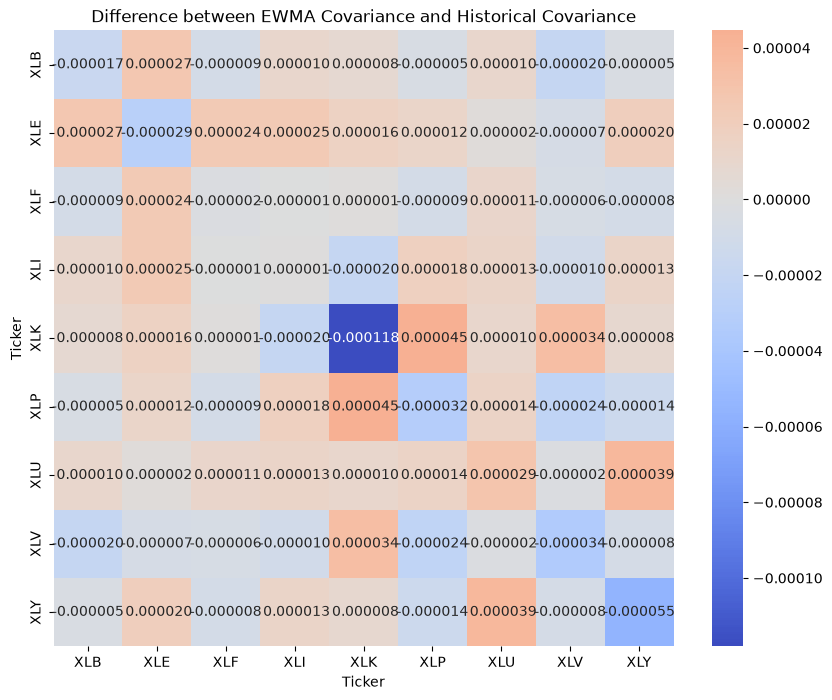

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cbar=True,
    center=0,
    cmap="coolwarm"
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

### EWMA vs Historical Covariance

The heatmap shows the difference between the EWMA and historical
covariance estimates for the latest observation window.

Positive values indicate that EWMA produces a higher covariance
estimate, while negative values indicate a lower estimate.

The differences confirm that EWMA responds differently from the
equally weighted historical estimator because it places greater
weight on recent observations. The largest diagonal difference is
observed for XLK, indicating a notable difference in the estimated
recent variance of the technology sector.

The difference matrix is symmetric, as expected for covariance
matrices.

In [81]:
historical_eigenvalues = np.linalg.eigvals(cov_last.values)

historical_eigenvalues

array([3.40389067e-04+0.j, 2.85480850e-04+0.j, 1.42383342e-04+0.j,
       1.00011374e-04+0.j, 7.75330965e-05+0.j, 2.12914430e-05+0.j,
       2.77820231e-05+0.j, 4.67498198e-05+0.j, 4.96535785e-05+0.j])

In [82]:
ewma_eigenvalues = np.linalg.eigvals(ewma_cov_last.values)

ewma_eigenvalues

array([2.89486095e-04+0.j, 1.55151081e-04+0.j, 1.47293681e-04+0.j,
       8.51638322e-05+0.j, 5.47093396e-05+0.j, 4.23124757e-05+0.j,
       2.85689400e-05+0.j, 1.31145957e-05+0.j, 1.65791704e-05+0.j])

In [83]:
print(
    "Historical minimum eigenvalues:",
    historical_eigenvalues.min()
    
)

print(
    "EWMA minimum eigenvalues:",
    ewma_eigenvalues.min()
)

Historical minimum eigenvalues: (2.1291442956670435e-05+0j)
EWMA minimum eigenvalues: (1.311459574918473e-05+0j)


In [84]:
tolerance = 1e-10

print(
    "Historical PSD:",
    historical_eigenvalues.min() >= -tolerance
)

print(
    "EWMA PSD:",
    ewma_eigenvalues.min() >= -tolerance
)

Historical PSD: True
EWMA PSD: True


In [85]:
sector_returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2010-01-05,0.003228,0.008129,0.018213,0.003525,-0.001290,0.000375,-0.011976,-0.009856,0.003660
2010-01-06,0.016851,0.011904,0.002003,0.002109,-0.011251,-0.000750,0.005844,0.010171,0.001328
2010-01-07,-0.007809,-0.001501,0.021123,0.010826,-0.003924,0.000000,-0.004543,0.003473,0.008258
2010-01-08,0.013841,0.006489,-0.005896,0.015851,0.006532,-0.003382,-0.000976,0.001574,-0.000329
2010-01-11,-0.005456,-0.001328,0.000657,0.010881,-0.003914,0.002631,0.010363,0.005648,-0.001976


In [86]:
sector_returns.shape

(4213, 9)

In [87]:
sector_returns.columns

Index(['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY'], dtype='str', name='Ticker')

In [88]:
window = 60

In [89]:
historical_cov = (
    sector_returns
    .rolling(window=window)
    .cov()
)

In [90]:
historical_cov.head()

Ticker             XLB  XLE  XLF  XLI  XLK  XLP  XLU  XLV  XLY
Date       Ticker                                             
2010-01-05 XLB     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLE     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLF     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLI     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
           XLK     NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN

In [91]:
historical_cov.shape

(37917, 9)

In [92]:
last_date = sector_returns.index[-1]

print(last_date)

2026-10-07 00:00:00


In [93]:
cov_last = historical_cov.loc[last_date]

cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000106,-0.000016,0.000029,0.000037,0.000022,0.000043,1.798284e-05,3.715504e-05,0.000044
XLE,-0.000016,0.000161,-0.000009,-0.000023,-0.000034,-0.000015,-2.393021e-06,-1.487657e-05,-0.000041
XLF,0.000029,-0.000009,0.000055,0.000032,0.000017,0.000025,9.659249e-06,1.715166e-05,0.000045
XLI,0.000037,-0.000023,0.000032,0.000091,0.000079,-0.000003,3.223805e-05,-7.724990e-06,0.000028
XLK,0.000022,-0.000034,0.000017,0.000079,0.000248,-0.000067,1.662183e-05,-5.837450e-05,0.000033
XLP,0.000043,-0.000015,0.000025,-0.000003,-0.000067,0.000091,1.609132e-05,5.871084e-05,0.000045
XLU,0.000018,-0.000002,0.000010,0.000032,0.000017,0.000016,8.862426e-05,-4.416094e-07,0.000007
XLV,0.000037,-0.000015,0.000017,-0.000008,-0.000058,0.000059,-4.416094e-07,1.036920e-04,0.000027
XLY,0.000044,-0.000041,0.000045,0.000028,0.000033,0.000045,7.297759e-06,2.702474e-05,0.000146


In [94]:
cov_last.shape

(9, 9)

In [95]:
cov_last.loc["XLK", "XLK"]

np.float64(0.0002482434330879459)

In [96]:
np.allclose(
    cov_last.values,
    cov_last.values.T
)

True

In [97]:
print(cov_last.loc["XLK", "XLF"])
print(cov_last.loc["XLF", "XLK"])

1.7045132271449324e-05
1.7045132271449324e-05


In [98]:
pd.Series(
    np.diag(cov_last),
    index = cov_last.columns,
    name = "Variance"
)

Ticker
XLB    0.000106
XLE    0.000161
XLF    0.000055
XLI    0.000091
XLK    0.000248
XLP    0.000091
XLU    0.000089
XLV    0.000104
XLY    0.000146
Name: Variance, dtype: float64

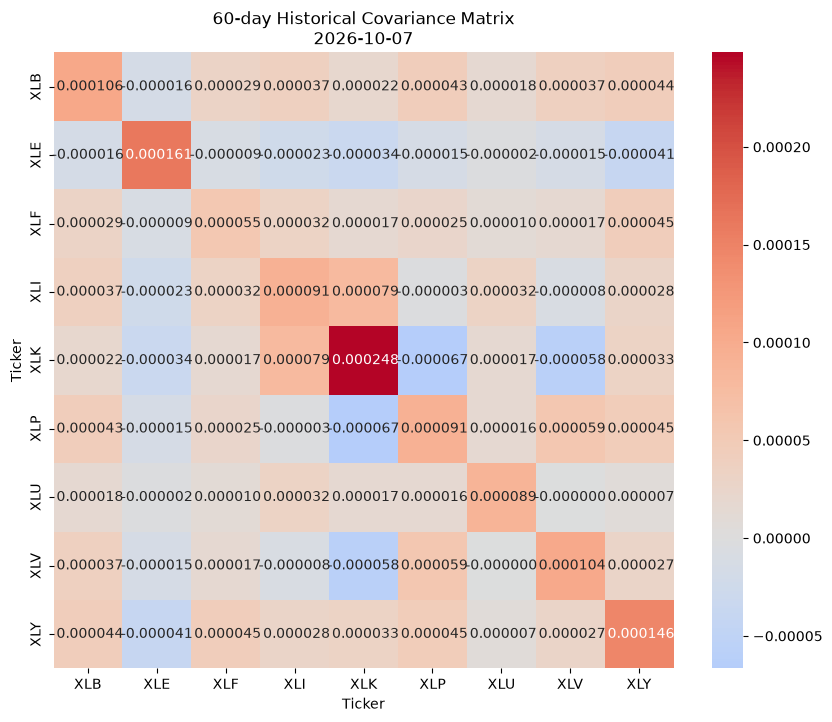

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (10, 8))

sns.heatmap(
    cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-day Historical Covariance Matrix\n{last_date.date()}"
)

plt.show()

In [100]:
first_valid_date = (
    historical_cov
    .dropna()
    .index
    .get_level_values(0)[0]
)

print("First valid covariance date:", first_valid_date)

First valid covariance date: 2010-03-31 00:00:00


In [101]:
latest_60_returns = sector_returns.iloc[-60:]

In [102]:
manual_cov = latest_60_returns.cov()

In [103]:
np.allclose(
    manual_cov.values,
    cov_last.values
)

True

### Historical Covariance Baseline

A rolling sample covariance estimator was implemented using a
60-trading-day lookback window. At each date, the covariance matrix
is estimated using only the observations contained within the
historical window.

The estimator produces a 9 × 9 covariance matrix corresponding to
the nine US sector ETFs.

The 60-day window is initially used for baseline implementation and
will be treated as an experimental design choice rather than assumed
to be universally optimal.

The historical covariance estimator provides a transparent empirical
baseline against which more adaptive and regularised covariance
estimators can be evaluated.

In [104]:
lambda_ = 0.94

In [105]:
latest_window = sector_returns.iloc[-window:]

latest_window.shape

(60, 9)

In [106]:
latest_window.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-07-14,0.001185,0.003694,0.001960,0.000443,0.012826,-0.013928,-0.000656,-0.019519,-0.001207
2026-07-15,-0.002768,-0.007933,0.006741,-0.002164,-0.011172,0.000599,-0.010340,0.000000,0.009446
2026-07-16,0.007693,0.009161,0.003354,0.000500,-0.022613,0.027648,0.005513,0.021932,0.002902
2026-07-17,-0.007099,0.011508,-0.008672,-0.004116,-0.010932,-0.007251,-0.006620,-0.004398,-0.016325
2026-07-20,-0.009944,0.004497,-0.003918,-0.007216,0.000683,-0.003881,-0.005105,-0.011488,-0.007216


In [107]:
latest_window.tail()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-10-01,-0.003291,0.019324,0.001123,0.009892,0.010469,-0.003355,0.006067,-0.013269,-0.000276
2026-10-02,0.006571,0.001912,0.000561,0.007738,0.010060,0.002487,0.003773,-0.000120,0.011241
2026-10-05,0.013014,0.009979,0.007265,0.000882,0.005590,0.006313,0.003509,0.007135,0.003447
2026-10-06,0.004636,0.004717,0.002410,0.008663,0.005311,0.009334,0.029338,-0.001674,0.011704
2026-10-07,-0.015196,-0.006136,-0.004826,-0.022039,-0.003024,-0.001223,-0.000243,0.010241,-0.003228


In [108]:
def ewma_covariance(returns_window, lambda_ =0.94):
    X = returns_window.values

    n = len(X)

    weights = np.array([
        (1 - lambda_) * lambda_ ** i
        for i in range(n)
    ])[::-1]

    weights = weights / weights.sum()

    mean = np.average(
        X,
        axis=0,
        weights=weights
    )

    X_centered = X - mean

    cov = (
        X_centered.T
        @ (X_centered * weights[:, None])
    )

    return pd.DataFrame(
        cov,
        index=returns_window.columns,
        columns=returns_window.columns
    )

In [109]:
lambda_ = 0.94
n = window

weights = np.array([
    (1 - lambda_) * lambda_ ** i
    for i in range(n)
])[::-1]

weights = weights / weights.sum()

In [110]:
weights[:5]

array([0.00159746, 0.00169943, 0.0018079 , 0.0019233 , 0.00204606])

In [111]:
weights[-5:]

array([0.04801732, 0.05108225, 0.05434282, 0.05781152, 0.06150161])

In [112]:
weights.sum()

np.float64(1.0)

<function matplotlib.pyplot.show(close=None, block=None)>

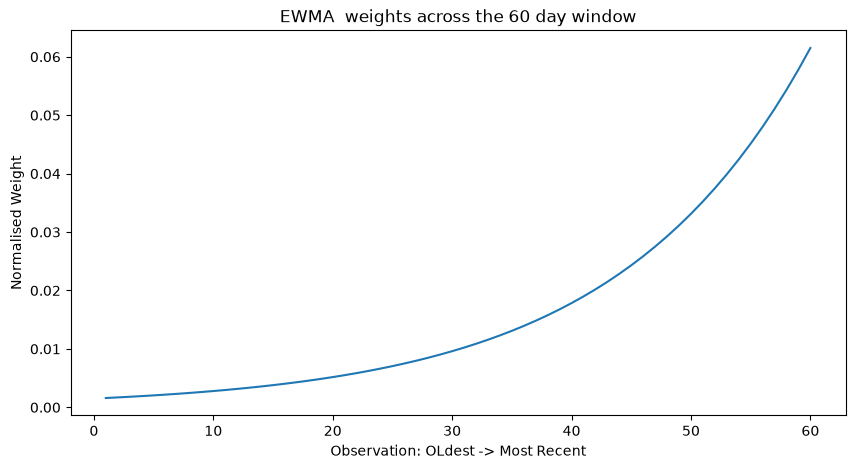

In [113]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, window + 1),
    weights
)

plt.title("EWMA  weights across the 60 day window")
plt.xlabel("Observation: OLdest -> Most Recent")
plt.ylabel("Normalised Weight")

plt.show

In [114]:
ewma_cov_last = ewma_covariance(
    latest_window,
    lambda_=0.94
)

ewma_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000088,1.087138e-05,0.000021,0.000047,0.000029,0.000037,2.794228e-05,0.000017,0.000040
XLE,0.000011,1.324277e-04,0.000014,0.000002,-0.000018,-0.000003,-1.109319e-07,-0.000022,-0.000021
XLF,0.000021,1.416960e-05,0.000053,0.000032,0.000018,0.000017,2.110577e-05,0.000011,0.000036
XLI,0.000047,1.816071e-06,0.000032,0.000092,0.000059,0.000014,4.522539e-05,-0.000018,0.000041
XLK,0.000029,-1.833327e-05,0.000018,0.000059,0.000130,-0.000022,2.667707e-05,-0.000024,0.000041
XLP,0.000037,-2.666238e-06,0.000017,0.000014,-0.000022,0.000059,3.016279e-05,0.000035,0.000032
XLU,0.000028,-1.109319e-07,0.000021,0.000045,0.000027,0.000030,1.172920e-04,-0.000003,0.000046
XLV,0.000017,-2.180030e-05,0.000011,-0.000018,-0.000024,0.000035,-2.661625e-06,0.000069,0.000019
XLY,0.000040,-2.105640e-05,0.000036,0.000041,0.000041,0.000032,4.613393e-05,0.000019,0.000091


In [115]:
ewma_cov_last.shape

(9, 9)

In [116]:
np.allclose(
    ewma_cov_last.values,
    ewma_cov_last.values.T
)

True

In [117]:
print(ewma_cov_last.loc["XLK", "XLF"])
print(ewma_cov_last.loc["XLF", "XLK"])

1.7811976497532868e-05
1.7811976497532868e-05


In [118]:
pd.Series(
    np.diag(ewma_cov_last),
    index=ewma_cov_last.columns,
    name="EWMA Variance"
)

Ticker
XLB    0.000088
XLE    0.000132
XLF    0.000053
XLI    0.000092
XLK    0.000130
XLP    0.000059
XLU    0.000117
XLV    0.000069
XLY    0.000091
Name: EWMA Variance, dtype: float64

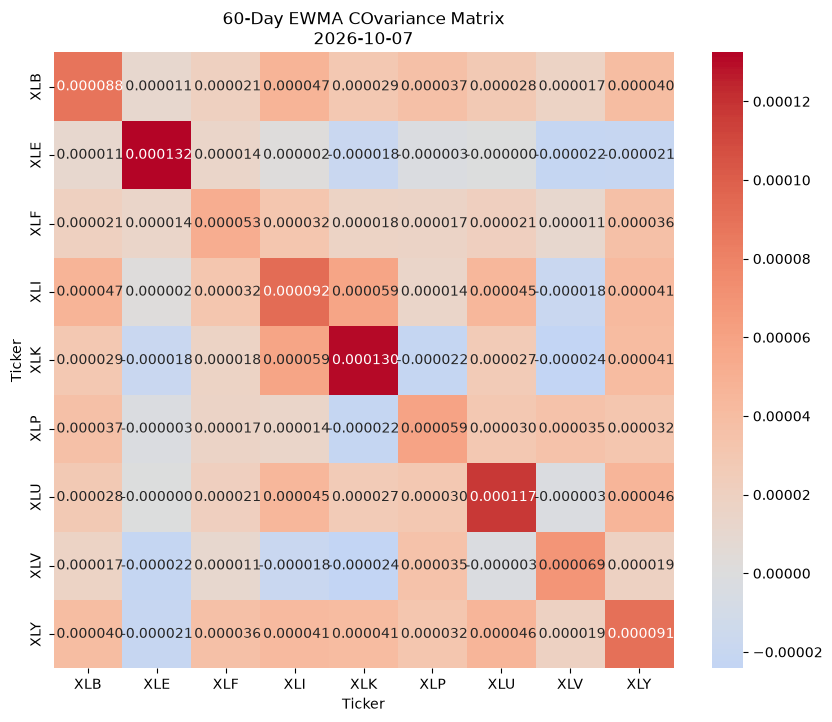

In [119]:
plt.figure(figsize=(10,8))

sns.heatmap(
    ewma_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    f"60-Day EWMA COvariance Matrix\n{last_date.date()}"
)

plt.show()

In [120]:
print(
    "Historical XLK-XLF:",
    cov_last.loc["XLK", "XLF"]
)

print(
    "EWMA XLK-XLF:",
    ewma_cov_last.loc["XLK", "XLF"]
)

Historical XLK-XLF: 1.7045132271449324e-05
EWMA XLK-XLF: 1.7811976497532868e-05


### EWMA Covariance Baseline

An Exponentially Weighted Moving Average (EWMA) covariance estimator
was implemented as a time-responsive baseline.

The estimator uses the same 60-trading-day information window as the
historical covariance baseline but assigns greater weight to more
recent observations through exponential decay.

An initial decay factor of λ = 0.94 is used for baseline
implementation. This value is treated as an experimental parameter
rather than assumed to be universally optimal.

EWMA provides a useful comparator because it introduces predetermined
temporal adaptation without learning estimator-selection or
combination behaviour from market-state variables.

In [121]:

print("Historical shape:", cov_last.shape)
print("EWMA shape:", ewma_cov_last.shape)

print(
    "Same assets:",
    list(cov_last.columns) == list(ewma_cov_last.columns)
)

Historical shape: (9, 9)
EWMA shape: (9, 9)
Same assets: True


In [122]:
cov_difference = ewma_cov_last - cov_last

cov_difference

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,-0.000017,0.000027,-8.796132e-06,1.032879e-05,7.630398e-06,-0.000005,0.000010,-0.000020,-0.000005
XLE,0.000027,-0.000029,2.365139e-05,2.469113e-05,1.573396e-05,0.000012,0.000002,-0.000007,0.000020
XLF,-0.000009,0.000024,-2.283161e-06,-5.532874e-07,7.668442e-07,-0.000009,0.000011,-0.000006,-0.000008
XLI,0.000010,0.000025,-5.532874e-07,7.497887e-07,-1.967680e-05,0.000018,0.000013,-0.000010,0.000013
XLK,0.000008,0.000016,7.668442e-07,-1.967680e-05,-1.180958e-04,0.000045,0.000010,0.000034,0.000008
XLP,-0.000005,0.000012,-8.736519e-06,1.764049e-05,4.460435e-05,-0.000032,0.000014,-0.000024,-0.000014
XLU,0.000010,0.000002,1.144652e-05,1.298734e-05,1.005524e-05,0.000014,0.000029,-0.000002,0.000039
XLV,-0.000020,-0.000007,-6.459300e-06,-1.042920e-05,3.416455e-05,-0.000024,-0.000002,-0.000034,-0.000008
XLY,-0.000005,0.000020,-8.282593e-06,1.345917e-05,8.388665e-06,-0.000014,0.000039,-0.000008,-0.000055


In [123]:
cov_difference.loc["XLK", "XLF"]

np.float64(7.668442260835438e-07)

In [124]:
np.allclose(
    ewma_cov_last.values,
    cov_last.values
)

False

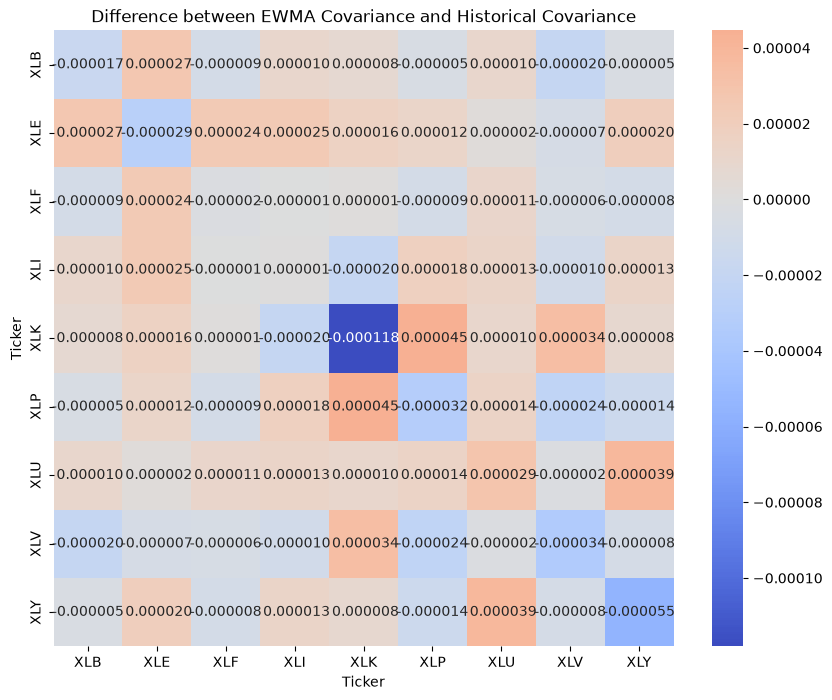

In [125]:
plt.figure(figsize=(10,8))

sns.heatmap(
    cov_difference,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title("Difference between EWMA Covariance and Historical Covariance")

plt.show()

In [126]:
variance_comparison = pd.DataFrame({
    "Historical": np.diag(cov_last),
    "EWMA": np.diag(ewma_cov_last)
}, index=cov_last.columns)

variance_comparison["Difference"] = (
    variance_comparison["EWMA"] - variance_comparison["Historical"]
)

variance_comparison

,Historical,EWMA,Difference
Ticker,,,
XLB,0.000106,0.000088,-1.736595e-05
XLE,0.000161,0.000132,-2.893464e-05
XLF,0.000055,0.000053,-2.283161e-06
XLI,0.000091,0.000092,7.497887e-07
XLK,0.000248,0.000130,-1.180958e-04
XLP,0.000091,0.000059,-3.182981e-05
XLU,0.000089,0.000117,2.866777e-05
XLV,0.000104,0.000069,-3.432089e-05
XLY,0.000146,0.000091,-5.548273e-05


In [127]:
frobenius_difference = np.linalg.norm(
    ewma_cov_last.values - cov_last.values,
    ord="fro"
)

print(
    "Frobenius distance between Historical and EWMA:",
    frobenius_difference)

Frobenius distance between Historical and EWMA: 0.00020705602094635335


### Historical vs EWMA Covariance

The Historical and EWMA estimators produce different covariance
estimates despite being calculated from the same 60-day information
window.

The Historical estimator treats observations approximately equally,
whereas EWMA assigns greater importance to recent observations.
Consequently, differences are observed in both individual asset
variances and cross-asset covariances.

These differences do not establish that either estimator is superior.
Their relative usefulness must be evaluated out of sample, particularly
through their downstream effect on portfolio risk and stability.

In [128]:
historical_eigenvalues = np.linalg.eigvalsh(
    cov_last.values
)

historical_eigenvalues

array([2.12914430e-05, 2.77820231e-05, 4.67498198e-05, 4.96535785e-05,
       7.75330965e-05, 1.00011374e-04, 1.42383342e-04, 2.85480850e-04,
       3.40389067e-04])

In [129]:
print(
    "Historical minimum eigenvalue:",
    historical_eigenvalues.min()
)

Historical minimum eigenvalue: 2.1291442956670363e-05


In [130]:
ewma_eigenvalues = np.linalg.eigvalsh(
    ewma_cov_last.values
)

ewma_eigenvalues

array([1.31145957e-05, 1.65791704e-05, 2.85689400e-05, 4.23124757e-05,
       5.47093396e-05, 8.51638322e-05, 1.47293681e-04, 1.55151081e-04,
       2.89486095e-04])

In [131]:
print(
    "EWMA minimum eigenvalue:",
    ewma_eigenvalues.min()
)

EWMA minimum eigenvalue: 1.3114595749184714e-05


In [132]:
tolerance = 1e-10

historical_psd = (
    historical_eigenvalues.min() >= -tolerance
)

ewma_psd = (
    ewma_eigenvalues.min() >= -tolerance
)

print("Historical PSD:", historical_psd)
print("EWMA PSD:", ewma_psd)

Historical PSD: True
EWMA PSD: True


In [133]:
eigenvalue_comparison = pd.DataFrame({
    "HIstorical": historical_eigenvalues,
    "EWMA": ewma_eigenvalues
})

eigenvalue_comparison.index = [
    f"Eigenvalue {i+1}"
    for i in range(len(eigenvalue_comparison))
]

eigenvalue_comparison

,HIstorical,EWMA
Eigenvalue 1,0.000021,0.000013
Eigenvalue 2,0.000028,0.000017
Eigenvalue 3,0.000047,0.000029
Eigenvalue 4,0.000050,0.000042
Eigenvalue 5,0.000078,0.000055
Eigenvalue 6,0.000100,0.000085
Eigenvalue 7,0.000142,0.000147
Eigenvalue 8,0.000285,0.000155
Eigenvalue 9,0.000340,0.000289


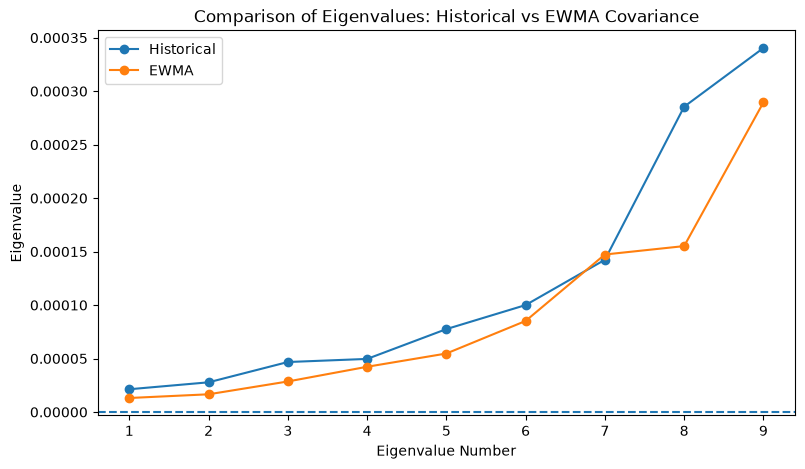

In [134]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, 10),
    historical_eigenvalues,
    marker="o",
    label="Historical"
)

plt.plot(
    range(1, 10),
    ewma_eigenvalues,
    marker="o",
    label="EWMA"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Eigenvalue Number")
plt.ylabel("Eigenvalue")
plt.title("Comparison of Eigenvalues: Historical vs EWMA Covariance")
plt.legend()

plt.show()

In [135]:
print(
    "HIstorical postivie definite:",
    historical_eigenvalues.min() >= tolerance
)

print(
    "EWMA postivie definite:",
    ewma_eigenvalues.min() >= tolerance
)

HIstorical postivie definite: True
EWMA postivie definite: True


In [136]:
historical_condition = np.linalg.cond(
    cov_last.values
)

wema_condition = np.linalg.cond(
    ewma_cov_last.values
)

print(
    "Historical condition number:",
    historical_condition
)

print(
    "EWMA condition number:",
    wema_condition
)


Historical condition number: 15.987130045967822
EWMA condition number: 22.073581267859318


### Covariance Validity and Eigenvalue Diagnostics

The Historical and EWMA covariance estimates were assessed for
positive semi-definiteness (PSD), an important mathematical property
of covariance matrices.

For a symmetric covariance matrix, PSD can be evaluated by examining
its eigenvalues. A matrix is PSD when its eigenvalues are
non-negative, subject to a small numerical tolerance for floating-point
error.

The minimum eigenvalue of each covariance estimate was therefore
examined alongside its overall eigenvalue spectrum. Condition numbers
were also calculated as an initial diagnostic of numerical
conditioning.

These checks establish mathematical and numerical diagnostics for the
baseline estimators before they are incorporated into downstream
portfolio optimisation.

In [137]:
from sklearn.covariance import LedoitWolf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [141]:
window = 60

latest_window = sector_returns.iloc[-window:].copy()

print("Window shape:", latest_window.shape)
print("Start date:", latest_window.index[0])
print("End date:", latest_window.index[-1])

Window shape: (60, 9)
Start date: 2026-07-14 00:00:00
End date: 2026-10-07 00:00:00


In [144]:
lw_model = LedoitWolf(
    assume_centered=False,
)

lw_model.fit(latest_window.values)

,"store_precision store_precision: bool, default=TrueSpecify if the estimated precision is stored.",True
,"assume_centered assume_centered: bool, default=FalseIf True, data will not be centered before computation.Useful when working with data whose mean is almost, but not exactlyzero.If False (default), data will be centered before computation.",False
,"block_size block_size: int, default=1000Size of blocks into which the covariance matrix will be splitduring its Ledoit-Wolf estimation. This is purely a memoryoptimization and does not affect results.",1000
Name,Type,Value
"covariance_ covariance_: ndarray of shape (n_features, n_features)Estimated covariance matrix.","ndarray[float64](9, 9)","[[ 0.,-0., 0.,..., 0., 0., 0.], [-0., 0.,-0.,...,-0.,-0.,-0.], [ 0.,-0., 0.,..., 0., 0., 0.], ..., [ 0.,-0., 0.,..., 0.,-0., 0.], [ 0.,-0., 0.,...,-0., 0., 0.], [ 0.,-0., 0.,..., 0., 0., 0.]]"
"location_ location_: ndarray of shape (n_features,)Estimated location, i.e. the estimated mean.","ndarray[float64](9,)","[-0., 0.,-0.,...,-0., 0.,-0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"precision_ precision_: ndarray of shape (n_features, n_features)Estimated pseudo inverse matrix.(stored only if store_precision is True)","ndarray[float64](9, 9)","[[12142.36, -174.71,-1009.55,..., -433.92,-2240.08,-1005.5 ], [ -174.71, 7260.27, -536.53,..., -277.87, 741.51, 1213.36], [-1009.55, -536.53,18081.28,..., 158.98, -891.63,-2983.6 ], ..., [ -433.92, -277.87, 158.98,...,11562.13, 564.31, 435.31], [-2240.08, 741.51, -891.63,..., 564.31,12603.12, -469.28], [-1005.5 , 1213.36,-2983.6 ,..., 435.31, -469.28, 9526.01]]"
"shrinkage_ shrinkage_: floatCoefficient in the convex combination used for the computationof the shrunk estimate. Range is [0, 1].",float64,0.2399


In [145]:
shrinkage_cov_last = pd.DataFrame(
    lw_model.covariance_,
    index=latest_window.columns,
    columns=latest_window.columns
)

shrinkage_cov_last

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,
XLB,0.000108,-0.000012,0.000022,0.000028,0.000016,0.000032,1.344138e-05,2.777176e-05,0.000033
XLE,-0.000012,0.000149,-0.000007,-0.000017,-0.000025,-0.000011,-1.788678e-06,-1.111958e-05,-0.000030
XLF,0.000022,-0.000007,0.000070,0.000024,0.000013,0.000019,7.219864e-06,1.282011e-05,0.000033
XLI,0.000028,-0.000017,0.000024,0.000097,0.000059,-0.000003,2.409652e-05,-5.774090e-06,0.000021
XLK,0.000016,-0.000025,0.000013,0.000059,0.000214,-0.000050,1.242409e-05,-4.363237e-05,0.000024
XLP,0.000032,-0.000011,0.000019,-0.000003,-0.000050,0.000097,1.202755e-05,4.388377e-05,0.000034
XLU,0.000013,-0.000002,0.000007,0.000024,0.000012,0.000012,9.484351e-05,-3.300836e-07,0.000005
XLV,0.000028,-0.000011,0.000013,-0.000006,-0.000044,0.000044,-3.300836e-07,1.061060e-04,0.000020
XLY,0.000033,-0.000030,0.000033,0.000021,0.000024,0.000034,5.454754e-06,2.019980e-05,0.000138


In [146]:
shrinkage_cov_last.shape

(9, 9)

In [147]:
shrinkage_intensity = lw_model.shrinkage_

print("Shrinkage intensity:", shrinkage_intensity)

Shrinkage intensity: 0.2398752194844856


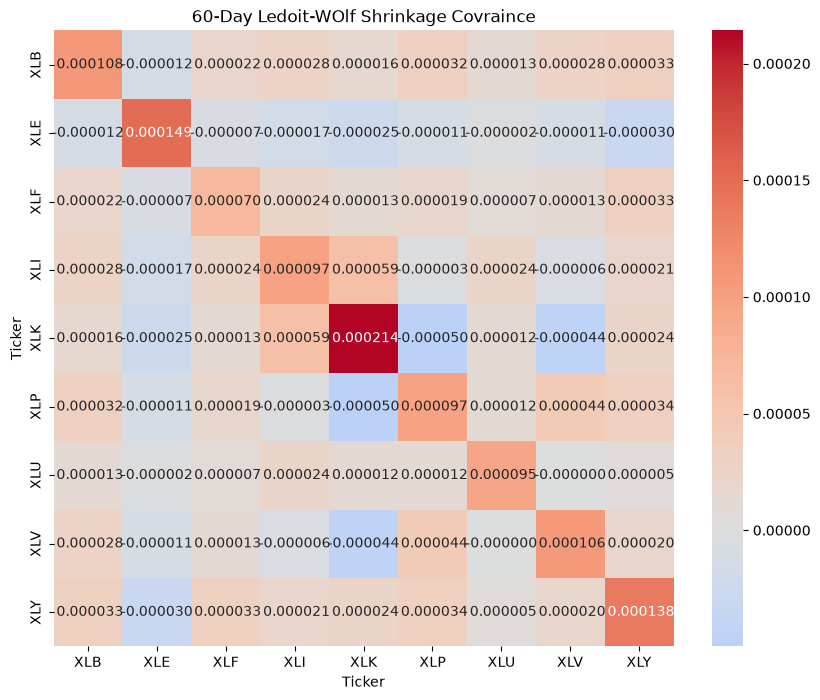

In [149]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    shrinkage_cov_last,
    annot=True,
    fmt=" .6f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "60-Day Ledoit-WOlf Shrinkage Covraince"
)

plt.show()

In [150]:
variance_comparison_3 = pd.DataFrame({
    "Historical": np.diag(cov_last.values),
    "EWMA": np.diag(ewma_cov_last.values),
    "Ledoit-Wolf": np.diag(shrinkage_cov_last.values)
}, index=sector_returns.columns)

variance_comparison_3

,Historical,EWMA,Ledoit-Wolf
Ticker,,,
XLB,0.000106,0.000088,0.000108
XLE,0.000161,0.000132,0.000149
XLF,0.000055,0.000053,0.000070
XLI,0.000091,0.000092,0.000097
XLK,0.000248,0.000130,0.000214
XLP,0.000091,0.000059,0.000097
XLU,0.000089,0.000117,0.000095
XLV,0.000104,0.000069,0.000106
XLY,0.000146,0.000091,0.000138


In [154]:
print(
    "HIstorical vs EWMA:",
    np.linalg.norm(
        cov_last.values - ewma_cov_last.values,
        ord="fro"
    )
)

print(
    "HIstorical vs Shrinkage:",
    np.linalg.norm(
        cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

print(
    "EWMA vs Shrinkage:",
    np.linalg.norm(
        ewma_cov_last.values - shrinkage_cov_last.values,
        ord="fro"
    )
)

HIstorical vs EWMA: 0.00020705602094635335
HIstorical vs Shrinkage: 8.291106042548206e-05
EWMA vs Shrinkage: 0.0001712253979944481


In [155]:
shrinkage_eigenvalues = np.linalg.eigvalsh(
    shrinkage_cov_last.values
)

print(
    "Minimum eigenvalue:",
    shrinkage_eigenvalues.min()
)

print(
    "Shrinkage PSD:",
    shrinkage_eigenvalues.min() >= -1e-10
)

Minimum eigenvalue: 4.451518460390881e-05
Shrinkage PSD: True


In [157]:
condition_comparison = pd.Series({
    "HIstorical": np.linalg.cond(cov_last.values),
    "EWMA": np.linalg.cond(ewma_cov_last.values),
    "Ledoit-Wolf": np.linalg.cond(shrinkage_cov_last.values)
})

condition_comparison

HIstorical     15.987130
EWMA           22.073581
Ledoit-Wolf     6.357979
dtype: float64

In [159]:
X = latest_window.values

# Maximum-likelihood sample covariance
S = np.cov(
    X,
    rowvar=False,
    bias=True
)

#Scaled identity target
mu = np.trace(S) / S.shape[0]

T = mu * np.eye(S.shape[0])

alpha = lw_model.shrinkage_

manual_shrinkage = (
    (1 - alpha) * S + alpha * T
)

print(
    "Manual formula matches sklearn:",
    np.allclose(
        manual_shrinkage,
        shrinkage_cov_last.values
    )
)

Manual formula matches sklearn: True


### Ledoit–Wolf Shrinkage Covariance Baseline

A Ledoit–Wolf linear shrinkage covariance estimator was implemented
as a regularised covariance-estimation baseline.

The estimator combines the sample covariance matrix with a scaled
identity target, using a data-driven shrinkage intensity.

A 60-trading-day estimation window was initially used to maintain
a comparable information window across the Historical, EWMA and
Ledoit–Wolf estimators.

The resulting 9 × 9 covariance matrix was assessed for symmetry,
positive semi-definiteness and numerical conditioning.

The shrinkage estimator represents a distinct regularisation-based
approach and provides an additional candidate covariance expert for
the proposed AdaptiveCov-X framework.

The final lookback-window and estimator settings will be determined
through the experimental design and validation process.

In [161]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize

In [162]:
def portfolio_variance(weights, covariance_matrix):
    return weights.T @ covariance_matrix @ weights

In [ ]:
def minimum_variance_portfolio(covariance_matrix):

    Sigma = np.asarray(
        covariance_matrix,
        dtype=float
    )

    n_assets = Sigma.shape[0]

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    })

    bounds = [
        (0.0, 1.0)
        for_in range(n_assets)
    ]

    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        args=(Sigma,),
        method = "SLSQP",
        bounds=bounds,
        constraints=constraints
        options={
            "ftol": 1e-12,
            "maxiter": 1000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed: {result.message}"
        )

    return result.x

